* **Metric:** weekly **ARPU** per user, in UAH — continuous, positive, right-skewed.
* **Baseline:** $\mu_0 = 250$ UAH (3 months of history for the old menu).
* **Cohorts:** `control` = old menu, `test` = new menu (combo deals).
* **Break-even = +15 UAH** — the **decision threshold**. Below this lift the extra revenue does not cover rebuilding the menu and logistics, so the feature is not worth shipping.
* **Design-MDE = +25 UAH** — the **planning threshold**. This is the “clear win” the team sizes the experiment to detect (power 0.8). It is a *different* number from break-even and is used **only** for power/sample planning, never as the ship rule.
* **Direction:** we only ship if the new menu is *better* $\rightarrow$ one-sided test, $H_1 : \mu_{\text{test}} > \mu_{\text{control}}$.
* **Significance level:** $\alpha = 0.05$.

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib_inline
import seaborn as sns
from scipy.stats import skew, t, norm, ttest_ind
from statsmodels.stats.proportion import proportion_confint
warnings.filterwarnings("ignore")
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")



In [2]:
from greenbowl_ab import load_my_ab, BASELINE, BREAKEVEN, DESIGN_MDE, ALPHA

STUDENT_ID = "ozhelezniakov@kse.org.ua"   
control, test = load_my_ab(STUDENT_ID)

print(f"control (old menu): n = {len(control)}")
print(f"test    (new menu): n = {len(test)}")
print(f"control (old menu) sample mean: {control.mean():.4f}")
print(f"test (new menu) sample mean: {test.mean():.4f}")
print(f"baseline mu0 = {BASELINE} UAH,  break-even = +{BREAKEVEN} UAH,  "
      f"design-MDE = +{DESIGN_MDE} UAH,  alpha = {ALPHA}")


control (old menu): n = 2291
test    (new menu): n = 2291
control (old menu) sample mean: 251.4381
test (new menu) sample mean: 244.5778
baseline mu0 = 250.0 UAH,  break-even = +15.0 UAH,  design-MDE = +25.0 UAH,  alpha = 0.05


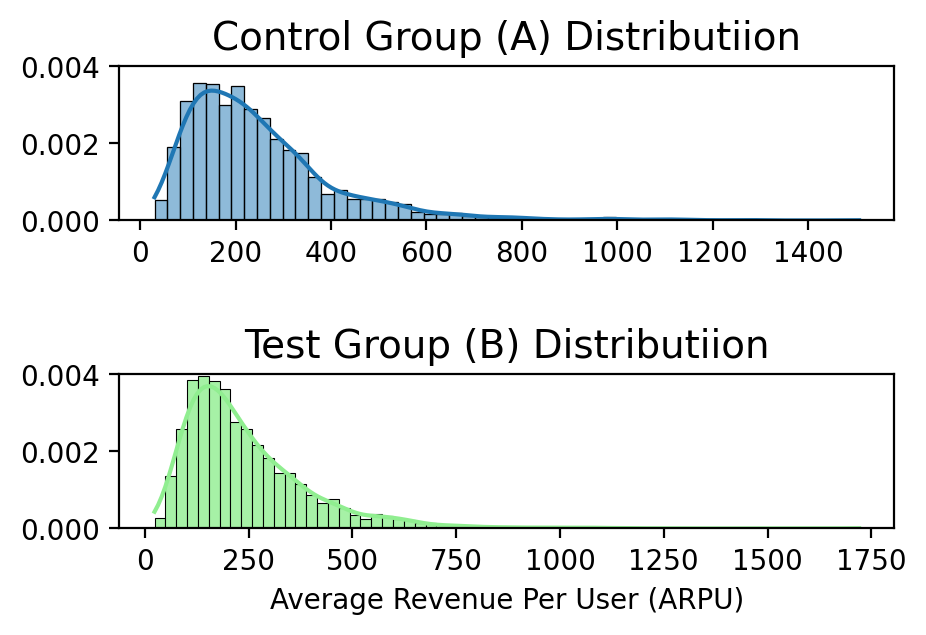

In [3]:
fig, ax = plt.subplots(2, 1, figsize = (5, 3))

sns.histplot(x = control, fill=True, ax = ax[0], stat='density', kde=True)
plt.subplots_adjust(hspace=1)

ax[0].set_title("Control Group (A) Distributiion", size = 14)
ax[0].set_xlabel("", size = 10)
ax[0].set_ylabel("")
ax[0].set_ylim(0, 0.004)
ax[0].set_yticks(np.arange(0, 0.005, 0.002))

sns.histplot(x = test, fill=True, ax = ax[1], stat='density', kde=True, color = "lightgreen", alpha = 0.8)
ax[1].set_title("Test Group (B) Distributiion", size = 14)
ax[1].set_xlabel("Average Revenue Per User (ARPU)", size = 10)
ax[1].set_ylabel("")
ax[1].set_ylim(0, 0.004)
ax[1].set_yticks(np.arange(0, 0.005, 0.002))

plt.show()

Розподіл нормльний чи скошений? 
* Цей розподіл не схожий на нормальний, оскільки має довгий правий хвіст і Skewness > 0. Тож я припущу, що це log-нормальний розподіл, також на користь цього говорить те, що розподіл не набуває від'ємних значень.
---
Чи рівні дисперісії?
* Ми можемо бачити, що дисперсії приблизно однакові. Проте все рівно краще використоувати поправку Велча

In [4]:
print(f"{'Sample':>7s} {'N':>6s} {'Mean':>8s} {'S':>5s} {'Skew':>11s}")
print(f"{'Conrol':>7s} {len(control):>9d} {control.mean():>7.2f} {np.std(control, ddof = 1):>8.2f} {skew(control):>6.2f}")
print(f"{'Test':>7s} {len(test):>9d} {test.mean():>7.2f} {np.std(test, ddof = 1):>8.2f} {skew(test):>6.2f}")

 Sample      N     Mean     S        Skew
 Conrol      2291  251.44   163.39   2.03
   Test      2291  244.58   156.31   2.05


Чи достатня вибірка, щоб використоувати t' а не t?
* Для одновибіркового тесту точно достатня. Це видно зі значень, які були на приктиці. Для двох вибіркового я точно не знаю, але теж думаю так.


In [5]:
print(fr"Equal variances: {((np.std(control, ddof = 1)/np.std(test, ddof = 1)) ** 0.5):.4f}")

Equal variances: 1.0224


Створюємо власну функцію для t-тестів та порівнюємо результати з вбудованою
* Як ми можемо бачити результати співпали: p-value, t-stats, df

In [6]:
def my_two_sample_t_test(a, b, alternative="two-sided",
                         equal_var=False, alpha=0.05, conf_int=True):
    """
    Two-sample t-test on the difference of means.
    Convention: T = (Ā − B̄)/SE; alternative is about a − b.
    equal_var=False → Welch (default); True → pooled (equal variances).
    """
    #a = np.asarray(a, dtype=float)
    #b = np.asarray(b, dtype=float)
    na, nb = len(a), len(b)
    ma, mb = a.mean(), b.mean()
    va, vb = a.var(ddof=1), b.var(ddof=1)
    diff   = ma - mb


    if equal_var:
        sp2 = ((na - 1) * va + (nb - 1) * vb) / (na + nb - 2)
        se  = np.sqrt(sp2 * (1 / na + 1 / nb))
        df  = na + nb - 2
    else:
        se  = np.sqrt(va / na + vb / nb)
        df  = (va / na + vb / nb) ** 2 / (
              (va / na) ** 2 / (na - 1) + (vb / nb) ** 2 / (nb - 1))

    t_stat = diff / se

    if alternative == "greater":
        p_value = t.sf(t_stat, df=df)
    elif alternative == "less":
        p_value = t.cdf(t_stat, df=df)
    elif alternative == "two-sided":
        p_value = 2 * t.sf(abs(t_stat), df=df)
    else:
        raise ValueError(f"Unknown alternative: {alternative!r}")

    if not conf_int:
        return p_value

    if alternative == "two-sided":
        crit    = t.ppf(1 - alpha / 2, df=df)
        ci_low, ci_high = diff - crit * se, diff + crit * se
    elif alternative == "greater":
        crit    = t.ppf(1 - alpha, df=df)
        ci_low, ci_high = diff - crit * se, np.inf
    else:  # less
        crit    = t.ppf(1 - alpha, df=df)
        ci_low, ci_high = -np.inf, diff + crit * se

    return {"diff": diff, "se": se, "t_stat": t_stat, "df": df,
            "p_value": p_value, "ci_low": ci_low, "ci_high": ci_high}

In [7]:
result_my_test = my_two_sample_t_test(test, control, alternative="greater",  equal_var=False)
print(f"Difference: {result_my_test["diff"]:<7.4f}")
print(f"DF: {result_my_test["df"]:>15.4f}")
print(f"SE: {result_my_test["se"]:>15.4f}")
print(f"T-stat: {result_my_test["t_stat"]:>11.4f}")
print(f"P-value: {result_my_test["p_value"]:>10.4f}")
print(f"CI: {result_my_test["ci_low"]:>10.4f} -- {result_my_test["ci_high"]:<7.4f}")

Difference: -6.8603
DF:       4571.0445
SE:          4.7241
T-stat:     -1.4522
P-value:     0.9267
CI:   -14.6323 -- inf    


In [8]:
result_bildin = ttest_ind(test, control, alternative="greater",  equal_var=False)
ci_95 = result_bildin.confidence_interval(confidence_level=0.95)
print(f"Difference: {result_my_test["diff"]:<7.4f}")
print(f"DF: {result_bildin.df:>15.4f}")
print(f"SE: {result_my_test["se"]:>15.4f}")
print(f"T-stat: {result_bildin.statistic:>11.4f}")
print(f"P-value: {result_bildin.pvalue:>10.4f}")
print(f"95% {ci_95.low:.4f} -- {ci_95.high:.4f}")


Difference: -6.8603
DF:       4571.0445
SE:          4.7241
T-stat:     -1.4522
P-value:     0.9267
95% -14.6323 -- inf


Рахуємо без поправки Велча та порівнюємо результати

In [9]:
result_bildin = ttest_ind(test, control, alternative="greater",  equal_var=True)
ci_95 = result_bildin.confidence_interval(confidence_level=0.95)
print(f"Difference: {result_my_test["diff"]:<7.4f}")
print(f"DF: {result_bildin.df:>15.4f}")
print(f"SE: {result_my_test["se"]:>15.4f}")
print(f"T-stat: {result_bildin.statistic:>11.4f}")
print(f"P-value: {result_bildin.pvalue:>10.4f}")
print(f"95% {ci_95.low:.4f} -- {ci_95.high:.4f}")

Difference: -6.8603
DF:       4580.0000
SE:          4.7241
T-stat:     -1.4522
P-value:     0.9267
95% -14.6323 -- inf


Чи потрібно вмикати поправку Велча? **Поріняяльна таблиця**


In [10]:
result_my_test_Welch = my_two_sample_t_test(test, control, alternative="greater",  equal_var=False)
result_my_test_without = my_two_sample_t_test(test, control, alternative="greater",  equal_var=True)
print(f"{"Welch":>18} {"Without":>14}")
print(f"Difference: {result_my_test_Welch["diff"]:<7.4f}", 
    f"{result_my_test_without["diff"]:>13.4f}")
print(f"DF: {result_my_test_without["df"]:>13}", 
    f"{result_my_test_without["df"]:>13}")
print(f"SE: {result_my_test_Welch["se"]:>15.4f}", 
    f"{result_my_test_without["se"]:>13.4f}")
print(f"T-stat: {result_my_test_Welch["t_stat"]:>11.4f}", 
    f"{result_my_test_without["t_stat"]:>13.4f}")
print(f"P-value: {result_my_test_Welch["p_value"]:>10.4f}", 
    f"{result_my_test_without["p_value"]:>13.4f}")
print(f"CI low: {result_my_test_Welch["ci_low"]:>11.4f}",
    f"{result_my_test_without["ci_low"]:13.4f}")

             Welch        Without
Difference: -6.8603       -6.8603
DF:          4580          4580
SE:          4.7241        4.7241
T-stat:     -1.4522       -1.4522
P-value:     0.9267        0.9267
CI low:    -14.6323      -14.6323


Перевіремо значення p-values при двозсторонній гіпотезі
* Як ми можемо бачити p-value (two-sided) = 2 * (1 - p-value (greater))

In [11]:
result_my_test = my_two_sample_t_test(test, control, alternative="two-sided",  equal_var=False)
print(f"P-value: {result_my_test["p_value"]:.4f}")
print(f"2 * (1 - Greater p-value) = {2 * (1 - result_my_test_Welch["p_value"]):.4f}")

P-value: 0.1465
2 * (1 - Greater p-value) = 0.1465


In [12]:
def my_two_sample_t_power(mean_diff, sd, n, alpha=0.05, alternative="greater"):
    """Power of the two-sample t-test (normal approximation, equal n)."""
    se = sd * np.sqrt(2 / n)
    if alternative in ("greater", "less"):
        z_a = norm.ppf(1 - alpha)
        return norm.cdf(abs(mean_diff) / se - z_a)
    if alternative == "two-sided":
        z_a = norm.ppf(1 - alpha / 2)
        return (norm.cdf(mean_diff / se - z_a) +
                norm.cdf(-mean_diff / se - z_a))
    raise ValueError(f"Unknown alternative: {alternative!r}")


def plan_t_experiment(sd, mde, alpha=0.05, target_power=0.8,
                      alternative="greater", n_lo=5, n_hi=1_000_000):
    """How many users per group are needed to detect an effect mde. Bisection."""
    if my_two_sample_t_power(mde, sd, n_hi, alpha, alternative) < target_power:
        return None
    while n_hi - n_lo > 1:
        n_mid = (n_lo + n_hi) // 2
        if my_two_sample_t_power(mde, sd, n_mid, alpha, alternative) >= target_power:
            n_hi = n_mid
        else:
            n_lo = n_mid
    return n_hi

Класифікація тесту на основі результатів

* Power = 0.8416 > 0.8. Вибірка достатня для того, щоб роботи висновки

* І без CI було зрозуміло, що в нас нема достатньо підстав відхилити $H_0$. Оскільки p-value = 0.9267, t-stat = -1.4522

* CI low дає, нам зрозуміти, що майже відхилися вліво на наш Break-even

In [13]:
mde_design = 25
df_1 = len(control) - 1
s = np.sqrt((df_1 * control.std(ddof = 1) ** 2 + df_1 * test.std(ddof = 1) ** 2) / df_1 *2 )
result = my_two_sample_t_power(mde_design, s, len(control))
print(f"Power of test: {result.item():.4f}")

Power of test: 0.8416


In [14]:
n = plan_t_experiment(s, mde_design)
print(f"Min N for power: {n}")
print(f"Actually per group: {len(control)}")

Min N for power: 2024
Actually per group: 2291


In [15]:
mde_Break = 15
ncontrol, ntest = len(control), len(test)
se  = np.sqrt(s * (1 / ncontrol + 1 / ntest))
diff = test.mean() - control.mean()
t_stat = (diff- mde_Break) / se
p = t.cdf(t_stat, df_1)
print(f"P(Effect > break-even) = {p:.1f}")

P(Effect > break-even) = 0.0



**Коли A\A тест може давати негативний результат**

* Занадто мала вибірка, тому p-value > alpha
* В 5% які випадків ми закладаємо як FPR
* Різне наповнення груп. Наприклад хотсь з групи B потрапив в групу 

In [16]:
def sample_lognormal_with_moments(target_mean, target_sd, size=1):
    """
    Generates samples from a lognormal distribution with a specific
    target mean and standard deviation.
    """
    sigma = np.sqrt(np.log(1 + (target_sd / target_mean) ** 2))
    
    mu = np.log(target_mean) - (sigma ** 2) / 2
    
    return np.random.lognormal(mean=mu, sigma=sigma, size=size)

def simulate_rejections(mu, sigma, n_test,
                        n_exps=10_000, alpha=0.05, equal_var=False,
                       alternative="two-sided"):
  ci_low = []
  ci_high = []
  p_values = []

  for _ in range(n_exps):

    sample_control = sample_lognormal_with_moments(mu, sigma, size = n_test)
    sample_test = sample_lognormal_with_moments(mu, sigma, size = n_test)

    result = my_two_sample_t_test(sample_control, sample_test, alternative=alternative, alpha=alpha, conf_int=True)

    p_values.append(result["p_value"])
    ci_low.append(result["ci_low"])
    ci_high.append(result["ci_high"])

  p_values = np.array(p_values)
  ci_low = np.array(ci_low)
  ci_high = np.array(ci_high)
  is_reject = 0.05 > p_values
  
  return {"p_values": p_values, "ci_low": ci_low, "ci_high": ci_high, "is_reject": is_reject}


In [17]:
mu = 250 
df_1 = len(control) - 1
n_exps = 100_000
s = np.sqrt((df_1 * control.std(ddof = 1) ** 2 + df_1 * test.std(ddof = 1) ** 2) / df_1 *2 )
result = simulate_rejections(mu, s, n_test = len(control), n_exps = 100_000)

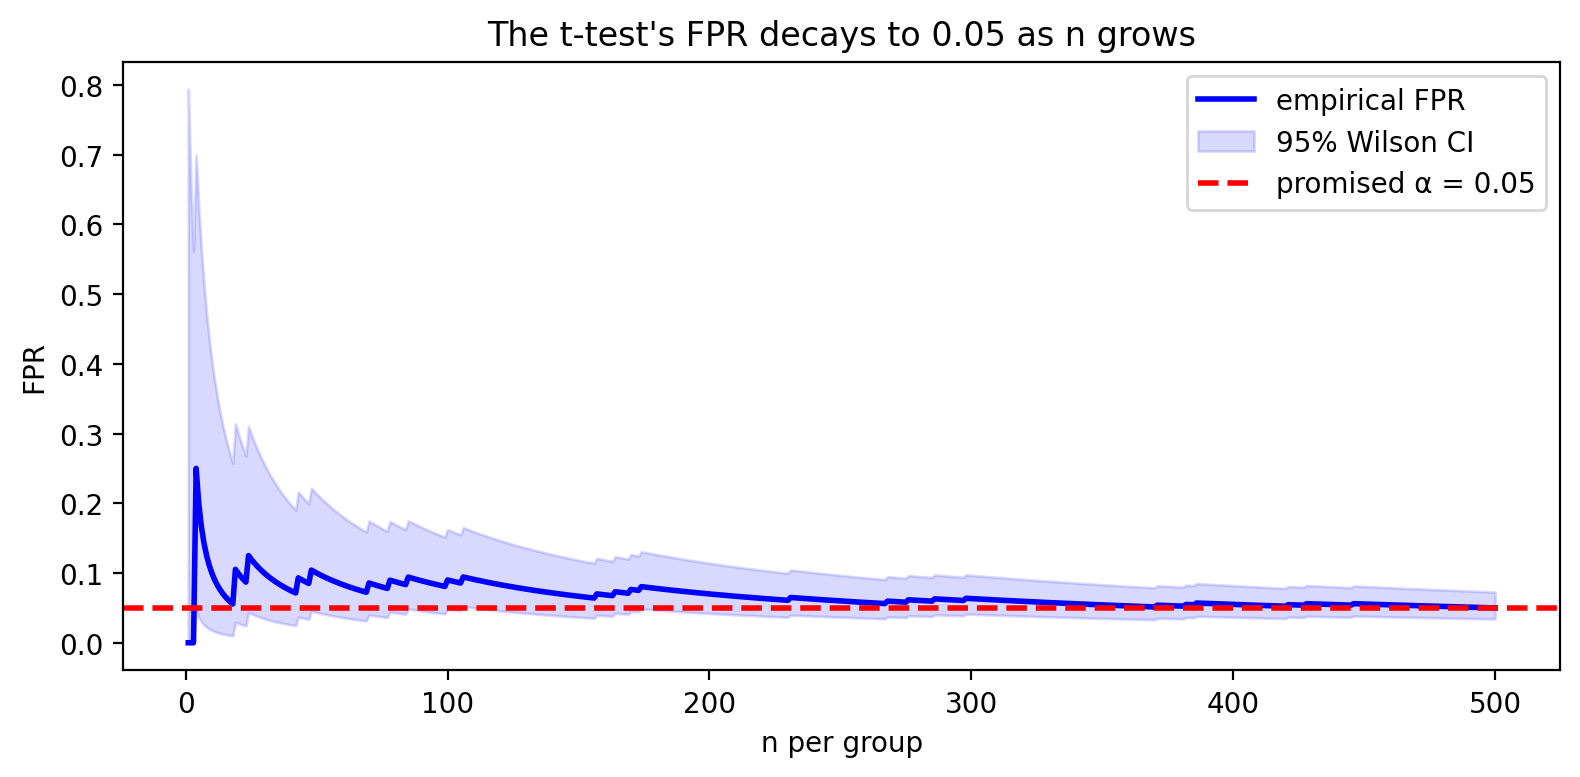

In [18]:
# Переробить 
mu = 250 
df_1 = len(control) - 1
n_exps = 500
s = np.sqrt((df_1 * control.std(ddof = 1) ** 2 + df_1 * test.std(ddof = 1) ** 2) / df_1 *2 )
result_500 = simulate_rejections(mu, s, n_test = len(control), n_exps = n_exps)

grid = np.arange(1, n_exps + 1, 1)
fprs = np.cumsum(result_500["is_reject"]) /  np.arange(1, len(result_500["is_reject"]) + 1)
ci_low, ci_high = proportion_confint(np.cumsum(result_500["is_reject"]), np.arange(1, n_exps + 1), alpha=0.05, method="wilson")

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(grid, fprs, color="blue", lw=2, ms=3, label="empirical FPR")
ax.fill_between(grid, ci_low, ci_high, color="blue", alpha=0.15, label="95% Wilson CI")
ax.axhline(0.05, color="red", ls="--", lw=2, label="promised α = 0.05")

ax.set_xlabel("n per group")
ax.set_ylabel("FPR")
ax.set_title("The t-test's FPR decays to 0.05 as n grows")
ax.legend()

plt.tight_layout()
plt.show()

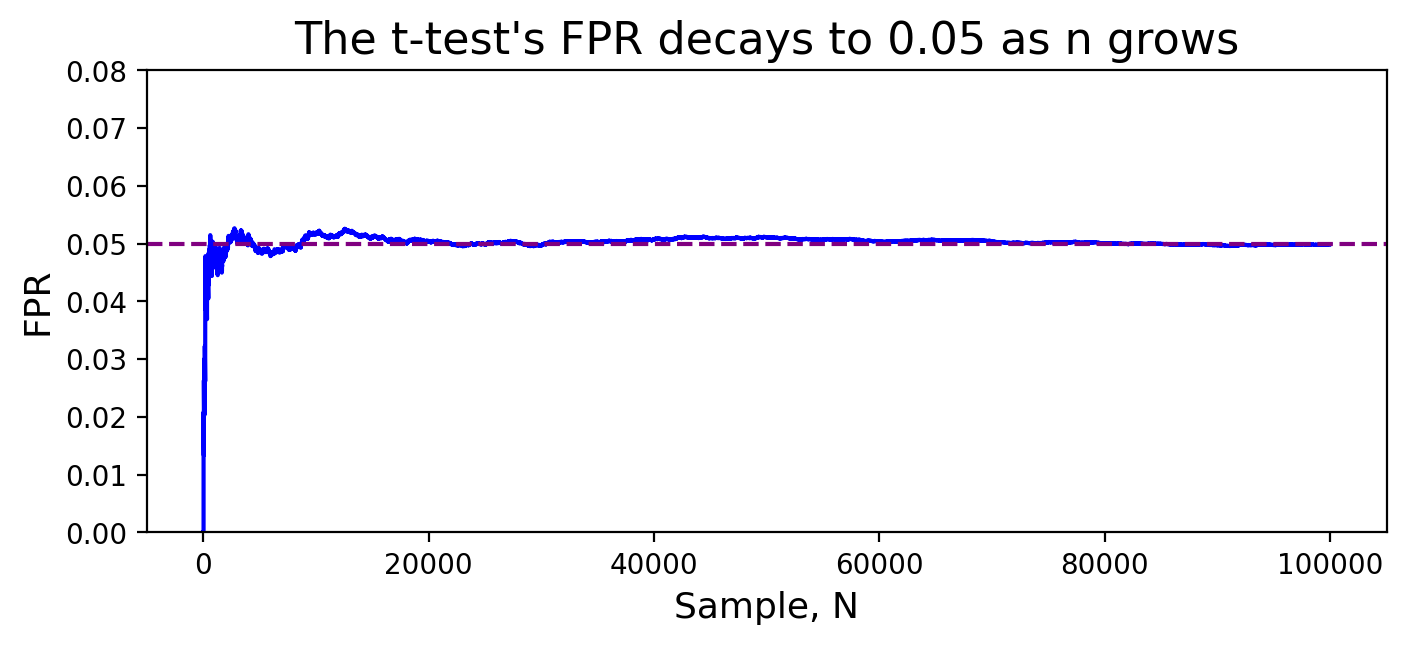

In [19]:

fprs = np.cumsum(result["is_reject"]) /  np.arange(1, len(result["is_reject"]) + 1)
fig, ax = plt.subplots(figsize = (8, 3))

ax.plot(fprs, color = "blue")
ax.axhline(0.05, color = "purple", linestyle = "--")


ax.set_title("The t-test's FPR decays to 0.05 as n grows", size = 16)
ax.set_xlabel("Sample, N", size = 13)
ax.set_ylabel("FPR", size = 13)
ax.set_ylim(0, 0.08)


plt.show()

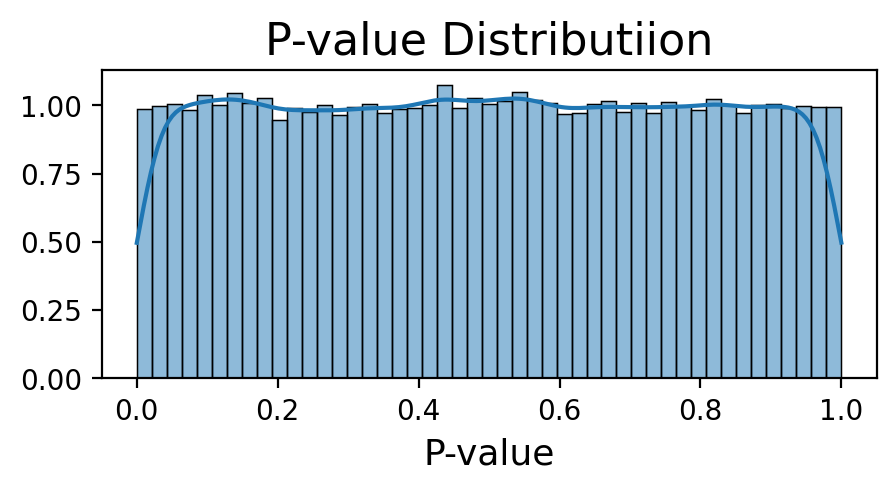

In [20]:
fig, ax = plt.subplots(figsize = (5,2))

sns.histplot(x = result["p_values"], fill=True, ax = ax, stat='density', kde=True)
ax.set_title("P-value Distributiion", size = 16)
ax.set_xlabel("P-value", size = 13)
ax.set_ylabel("")

plt.show()

Фінальні рекомендації

* Експеремнт не надав очікуваного результату
* Варто повернути старе меню або проводити ще один тест